# Which AlphaEarth dimensions does the TCN rely on?

The temporal convolutional network (TCN, `models.TemporalConvolutionalNetwork`) predicts whether a pixel that was wetland in 2019 is developed land by 2024 (NLCD). Its inputs are the 64 AlphaEarth embedding dimensions for 2017, 2018 and 2019, plus the pixel's distance to developed land in 2019.

AlphaEarth dimensions have no names. Dimension `A12` isn't "vegetation" or "water", it's just one axis of a learned 64 dimensional space. Still, it's worth asking whether the model leans on a few dimensions or spreads its attention over all 64. If a handful carry the signal, they're the place to start interpreting the embeddings, and maybe a reason to build a smaller model.

The plan:

1. Check that the models are worth interpreting at all: validation AUPRC against a linear baseline.
2. Read the first convolution layer's weights and turn them into one importance score per dimension. Raw weight sizes are misleading, so this takes three corrections, each explained where it's made.
3. Check that the ranking is stable across the 5 cross validation folds. A ranking that changes from fold to fold doesn't tell us anything.
4. Split each dimension's weights into a "level" part and a "change between years" part.
5. Cross check against permutation importance, which measures what the whole network actually uses, not just the first layer.
6. Compare against the linear baseline's coefficients.

**Before running this notebook**, train the models once from the repo root:

```
python weight_analysis_train.py
```

That trains a TCN and a linear model on each of the 5 spatially blocked folds of `data/arrays_2019_2024` (about 2 hours on the T4). It saves the checkpoints, the TCN's weights from before training, and some input statistics to `results/tcn_weight_analysis/`. This notebook only reads those files, so rerunning it is cheap. Permutation importance (section 5) takes several minutes the first time and is cached to the same folder after that.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import models  # noqa: E402, needs ROOT on the path first

RUN = ROOT / "results/tcn_weight_analysis"
ARRAY_DIR = ROOT / "data/arrays_2019_2024"
FIG_DIR = ROOT / "results/figures/model_weight_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

N_FOLDS = 5
N_DIMS = 64
YEARS = (2017, 2018, 2019)
N_YEARS = len(YEARS)
DIM_NAMES = np.array([f"A{d:02d}" for d in range(N_DIMS)])

missing = [k for k in range(N_FOLDS) if not (RUN / f"fold_{k}" / "linear_best.ckpt").exists()]
if missing:
    raise FileNotFoundError(f"folds {missing} have no saved models. Run python weight_analysis_train.py "
                            f"from the repo root first.")

# blue and orange from the colorblind checked reference palette, gray for "before training"
C_TCN, C_LIN, C_INIT = "#2a78d6", "#eb6834", "#9a9893"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 15, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")

## 1. Are the models any good?

There's no point interpreting a model that hasn't learned anything, so first, how well do they do.

Conversion to developed land is rare: roughly 1 in 350 wetland pixels. On data that imbalanced, accuracy is useless (predicting "never converts" scores 99.7%). So we use **AUPRC**, the area under the precision recall curve. A model that guesses at random gets an AUPRC equal to the positive rate, about 0.003 here, so the "lift over chance" column is the more readable number.

Each fold holds out about a fifth of the 10 km spatial blocks for validation. Holding out whole blocks matters because neighboring pixels are nearly identical. A random pixel split would put a pixel's neighbors in the training set and make the scores look far better than they really are.

Precision and recall at a 0.5 threshold are shown for completeness, but don't read much into them. The model's scores aren't calibrated probabilities (it's trained on batches with 1 positive in 32, not 1 in 350), so 0.5 isn't a meaningful cutoff. AUPRC doesn't depend on a threshold.

In [2]:
info = [json.loads((RUN / f"fold_{k}" / "fold_info.json").read_text()) for k in range(N_FOLDS)]

perf = pd.DataFrame([{
    "fold": i["fold"],
    "val pixels": i["n_val_rows"],
    "val positives": i["val_positives"],
    "positive rate": i["val_positive_rate"],
    "linear AUPRC": i["linear_val"]["auprc"],
    "TCN AUPRC": i["tcn_val"]["auprc"],
    "TCN lift over chance": i["tcn_val"]["auprc"] / i["val_positive_rate"],
    "TCN precision at 0.5": i["tcn_val"]["precision"],
    "TCN recall at 0.5": i["tcn_val"]["recall"],
} for i in info]).set_index("fold")
perf.loc["mean"] = perf.mean()
perf.style.format({"val pixels": "{:,.0f}", "val positives": "{:,.0f}", "positive rate": "{:.3%}",
                   "linear AUPRC": "{:.3f}", "TCN AUPRC": "{:.3f}", "TCN lift over chance": "{:.0f}x",
                   "TCN precision at 0.5": "{:.3f}", "TCN recall at 0.5": "{:.3f}"})

,val pixels,val positives,positive rate,linear AUPRC,TCN AUPRC,TCN lift over chance,TCN precision at 0.5,TCN recall at 0.5
fold,,,,,,,,
0,"11,866,780","29,390",0.248%,0.070,0.086,35x,0.123,0.241
1,"11,845,125","39,123",0.330%,0.099,0.121,37x,0.134,0.278
2,"11,841,089","30,462",0.257%,0.083,0.112,43x,0.118,0.306
3,"11,854,236","30,405",0.256%,0.091,0.117,45x,0.136,0.267
4,"11,860,101","36,528",0.308%,0.091,0.123,40x,0.138,0.330
mean,"11,853,466","33,182",0.280%,0.087,0.112,40x,0.130,0.284


## 2. What the first layer looks like

The TCN's first layer is `nn.Conv1d(64, 128, kernel_size=2)`. Before it runs, the 192 embedding columns are reshaped into a little time series: 64 channels (one per AlphaEarth dimension) by 3 time steps (2017, 2018, 2019).

```
                       2017   2018   2019
              A00  [   x      x      x   ]
input         A01  [   x      x      x   ]       64 channels by 3 years
              ...
              A63  [   x      x      x   ]
```

The convolution has 128 filters. Each filter looks at two consecutive years at a time and slides along: first (2017, 2018), then (2018, 2019). So the weight tensor `W` has shape `(128, 64, 2)`:

* axis 0: which of the 128 filters (output channels)
* axis 1: which AlphaEarth dimension the weight reads
* axis 2: the two kernel "taps". Tap 0 multiplies the earlier year of the pair, tap 1 the later year.

Filter `c` on the year pair (t, t+1) computes

$$\text{out}_c = b_c + \sum_{d=0}^{63} \big( W_{c,d,0}\, x_{d,t} + W_{c,d,1}\, x_{d,t+1} \big)$$

So every weight connected to dimension `d` sits in the slice `W[:, d, :]`, 128 filters by 2 taps. If the model ignores dimension `d`, that whole slice should be near zero.

The order of the 128 filters is arbitrary. Two models trained from different random starts can learn the same filters in a different order, so comparing filter 7 in fold 0 with filter 7 in fold 1 means nothing. Input dimensions, on the other hand, are fixed: `A12` is `A12` in every fold. That's why every score below **adds up over the filters** and keeps only the dimension axis.

In [3]:
def load_state_dict(path):
    obj = torch.load(path, map_location="cpu", weights_only=False)
    # Lightning checkpoints wrap the weights, the init file is a bare state_dict
    return obj.get("state_dict", obj)


W, W_init, bn_scale, col_std, sum_std, diff_std, lin_coef = [], [], [], [], [], [], []
for k in range(N_FOLDS):
    d = RUN / f"fold_{k}"
    sd = load_state_dict(d / "tcn_best.ckpt")
    W.append(sd["tcn_block.0.weight"].numpy())
    W_init.append(load_state_dict(d / "tcn_init.pt")["tcn_block.0.weight"].numpy())

    # BatchNorm1d in eval mode: y = gamma * (x - running_mean) / sqrt(running_var + eps) + beta.
    # eps is the PyTorch default, models.py doesn't override it.
    gamma, var = sd["tcn_block.1.weight"].numpy(), sd["tcn_block.1.running_var"].numpy()
    bn_scale.append(gamma / np.sqrt(var + 1e-5))

    stats = np.load(d / "emb_stats.npz")
    col_std.append(stats["std"].reshape(N_YEARS, N_DIMS))  # columns are year major
    sum_std.append(stats["sum_std"])
    diff_std.append(stats["diff_std"])

    lin_coef.append(load_state_dict(d / "linear_best.ckpt")["model.0.weight"].numpy()[0])

W, W_init = np.stack(W), np.stack(W_init)      # (fold, 128 filters, 64 dims, 2 taps)
bn_scale = np.stack(bn_scale)                  # (fold, 128)
col_std = np.stack(col_std)                    # (fold, year, 64)
sum_std, diff_std = np.stack(sum_std), np.stack(diff_std)  # (fold, year pair, 64)
lin_coef = np.stack(lin_coef)                  # (fold, 193): dist, then 192 embedding columns
print("first layer weights:", W.shape)


def per_dim_norm(w):
    # L2 norm over filters and taps, leaving one number per (fold, dim)
    return np.sqrt((w ** 2).sum(axis=(1, 3)))

first layer weights: (5, 128, 64, 2)


### Score 1: raw weight size

The simplest score is the L2 norm of `W[:, d, :]`: square all 256 weights for dimension `d`, add them up, take the square root. That gives one number per dimension.

### Why that isn't enough, part 1: the weights didn't start at zero

PyTorch initializes conv weights randomly, uniform between plus and minus $1/\sqrt{\text{fan in}}$ = $1/\sqrt{64 \times 2} \approx 0.088$. Training then nudges them. This model was trained without weight decay (no penalty pulling weights toward zero), so the weights for a dimension the model finds useless just stay roughly where they started. They don't shrink.

That means a raw weight norm is part "what training did" and part "luck of the initial draw". The training script saved the weights from before the first gradient step, so we can measure how much of the raw ranking is just the initial draw: correlate the raw norm with the norm of the starting weights. We use Spearman rank correlation, which compares the order of two rankings and ignores the actual values. 1 means identical order, 0 means unrelated.

In [4]:
raw = per_dim_norm(W)
init = per_dim_norm(W_init)

rho_raw_init = [spearmanr(raw[k], init[k])[0] for k in range(N_FOLDS)]
print("Spearman(raw norm, norm at initialization) per fold:", np.round(rho_raw_init, 2))
print(f"norm at initialization: mean {init.mean():.3f}, smallest dim {init.min():.3f}, largest {init.max():.3f}")
print(f"norm after training:    mean {raw.mean():.3f}, smallest dim {raw.min():.3f}, largest {raw.max():.3f}")

Spearman(raw norm, norm at initialization) per fold: [ 0.04 -0.04  0.05 -0.03  0.23]
norm at initialization: mean 0.816, smallest dim 0.763, largest 0.902
norm after training:    mean 2.442, smallest dim 1.576, largest 3.969


If that correlation is well above 0, the raw ranking partly reflects how the weights started.

### Score 2: how far the weights moved during training

So instead of the size of `W`, use the size of the change, `W - W_init`, for each dimension. Training only moves a weight if moving it lowers the loss, so a dimension the model has no use for should barely move.

### Why that isn't enough, part 2: input scale and BatchNorm

Two more things change what a given weight size means.

**Input spread.** A weight's effect on the output is weight times input. The embedding dimensions aren't standardized, and their standard deviation across wetland pixels differs by about 3x between dimensions (printed below). A dimension with a small spread needs a bigger weight to move the output by the same amount. So we multiply each dimension's weights by that dimension's standard deviation, computed on the training pixels only.

**BatchNorm.** Right after the conv comes `BatchNorm1d(128)`. At inference time it rescales each filter's output by $\gamma_c / \sqrt{\sigma^2_c + \epsilon}$. A filter BatchNorm scales down a lot matters less downstream, however large its weights. Multiplying each filter's weights by its BatchNorm scale "folds" BatchNorm into the conv, the same trick deployment tools use to merge the two layers.

### Score 3 (the one we'll use): effective weight change

$$\text{score}_d = \Big\lVert\, s_c \cdot (W_{c,d,\tau} - W^{\text{init}}_{c,d,\tau}) \cdot \sigma_{d,\tau} \,\Big\rVert_{\text{over } c,\ \tau}$$

where $s_c$ is filter $c$'s BatchNorm scale and $\sigma_{d,\tau}$ is the standard deviation of dimension $d$ in the years tap $\tau$ reads (tap 0 reads 2017 and 2018, tap 1 reads 2018 and 2019). Roughly, it's how much training changed the first layer's response to a typical change in dimension $d$.

In [5]:
print(f"per dim input std (fold 0, 2019): smallest {col_std[0, -1].min():.3f}, largest {col_std[0, -1].max():.3f}")

moved = per_dim_norm(W - W_init)

# tap 0 reads years 0..n-2 as the kernel slides, tap 1 reads years 1..n-1
tap_std = np.stack([col_std[:, :-1].mean(axis=1), col_std[:, 1:].mean(axis=1)], axis=-1)  # (fold, 64, 2)
effective = per_dim_norm(bn_scale[:, :, None, None] * (W - W_init) * tap_std[:, None, :, :])

def mean_fold_spearman(a, b):
    return np.mean([spearmanr(a[k], b[k])[0] for k in range(N_FOLDS)])

scores = {"raw norm": raw, "norm at init": init, "moved": moved, "effective change": effective}
pd.DataFrame([[mean_fold_spearman(scores[a], scores[b]) for b in scores] for a in scores],
             index=scores.keys(), columns=scores.keys()).round(2)

per dim input std (fold 0, 2019): smallest 0.042, largest 0.128


,raw norm,norm at init,moved,effective change
raw norm,1.00,0.05,0.97,-0.10
norm at init,0.05,1.00,0.02,0.03
moved,0.97,0.02,1.00,-0.16
effective change,-0.10,0.03,-0.16,1.00


The table shows how much each correction reorders the dimensions (Spearman, averaged over the 5 folds). If "moved" and "effective change" correlate less than perfectly with "raw norm", the corrections changed the story.

### The ranking

Below, dimensions are sorted by their effective change score averaged over the 5 folds. The error bars show the standard deviation across folds. What we're looking for: is there a clear head (a few dimensions far above the rest), or a smooth slope where every dimension gets about the same treatment?

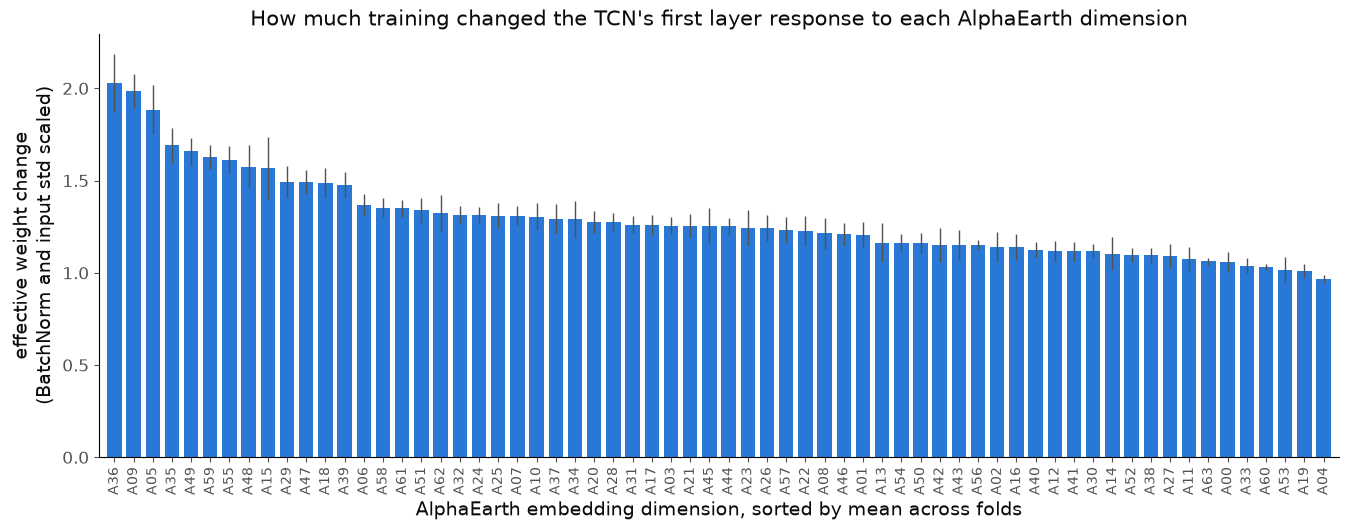

top dim / median dim: 1.62x
share of total score held by the top 10 dims: 20.8% (10/64 = 15.6% if every dim were equal)
top 10: A36, A09, A05, A35, A49, A59, A55, A48, A15, A29


In [6]:
def ranked_bar(score, color, ylabel, title, name):
    mean, sd = score.mean(axis=0), score.std(axis=0)
    order = np.argsort(mean)[::-1]
    fig, ax = plt.subplots(figsize=(16, 5.5))
    ax.bar(np.arange(N_DIMS), mean[order], yerr=sd[order], color=color, width=0.75,
           error_kw=dict(ecolor=MUTED, lw=1, capsize=0))
    ax.set_xticks(np.arange(N_DIMS), DIM_NAMES[order], rotation=90, fontsize=10)
    ax.set_xlim(-0.8, N_DIMS - 0.2)
    ax.set_xlabel("AlphaEarth embedding dimension, sorted by mean across folds")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    save(fig, name)
    plt.show()
    return order


eff_order = ranked_bar(
    effective, C_TCN, "effective weight change\n(BatchNorm and input std scaled)",
    "How much training changed the TCN's first layer response to each AlphaEarth dimension",
    "first_layer_effective_change",
)
mean_eff = effective.mean(axis=0)
print(f"top dim / median dim: {mean_eff.max() / np.median(mean_eff):.2f}x")
print(f"share of total score held by the top 10 dims: {np.sort(mean_eff)[::-1][:10].sum() / mean_eff.sum():.1%} "
      f"(10/64 = {10/64:.1%} if every dim were equal)")
print("top 10:", ", ".join(DIM_NAMES[eff_order[:10]]))

### A warning sign: is the score just the input spread?

The effective score is (weight change) times (input std). If the weight change came out about the same for every dimension, the score would just reproduce the input std ranking and say nothing about the model. So check how strongly each piece correlates with input std.

In [7]:
dim_std = col_std.mean(axis=1)   # (fold, 64), averaged over the three years
print(f"Spearman(effective score, input std): {mean_fold_spearman(effective, dim_std):.2f}")
print(f"Spearman(weight change, input std):   {mean_fold_spearman(moved, dim_std):.2f}")
print(f"weight change across dims: smallest {moved.min(axis=1).mean():.2f}, median {np.median(moved, axis=1).mean():.2f}, "
      f"largest {moved.max(axis=1).mean():.2f} (mean over folds)")
print(f"input std across dims:     largest / smallest = {(dim_std.max(axis=1) / dim_std.min(axis=1)).mean():.2f}")

Spearman(effective score, input std): 0.81
Spearman(weight change, input std):   -0.64
weight change across dims: smallest 1.55, median 2.17, largest 2.93 (mean over folds)
input std across dims:     largest / smallest = 2.82


A large positive first number means the effective ranking mostly reflects which dimensions have a wide spread, not which ones the model learned to care about.

The likely reason is the optimizer. The model is trained with **Adam**, which divides each weight's update by a running average of that weight's own gradient size. That's what makes Adam train well without careful learning rate tuning, but it also means every weight takes steps of about the same size (roughly the learning rate) whether its gradient is large or tiny. How far a weight ends up from its start then depends mostly on whether its gradient kept pointing the same way, not on how strong it was. With plain gradient descent, weights for useless inputs would barely move. With Adam they wander about as far as everything else.

The second number shows a partial correction: dimensions with a small spread did get somewhat larger weight changes, which is what you'd expect if the model compensates for scale. But the compensation is much weaker than the 3x spread in input std, so the std dominates.

**The takeaway, which is the main methods lesson of this notebook: in a network trained with Adam and no weight decay, first layer weight magnitudes are a weak and easily confounded measure of importance.** That's why sections 5 and 6 matter. Permutation importance measures what the model does with each dimension directly, and it's the number to trust if the two disagree.

## 3. Is the ranking stable across folds?

A ranking only means something if it repeats. Each fold's model was trained from a different random start on a different 80% of the spatial blocks. If dimension `A12` comes out on top because the data really points there, it should come out near the top in every fold. If it's on top by chance, the folds will disagree.

Two checks:

* **Spearman correlation between folds** of the full 64 dimension ranking. Near 0 means the folds don't agree on anything.
* **Top 10 overlap**: how many of fold i's top 10 dimensions are also in fold j's top 10. If the rankings were random, the expected overlap is $10 \times 10 / 64 \approx 1.6$.

Two caveats:

* Any two folds share 60% of their training blocks (3 of the 4 training folds), so they aren't fully independent experiments. Agreement here is a necessary condition, not proof.
* After the check above, the effective score is suspect for a specific reason: input std is almost identical in every fold (it's the same Florida wetlands), so a score that mostly tracks input std will look stable across folds *even if the weights carry no information*. The fairer stability test for the weights themselves is the unscaled "moved" score, printed below as well.

In [8]:
def fold_agreement(score, top=10):
    rho = spearmanr(score.T)[0]  # (fold, fold)
    tops = [set(np.argsort(s)[::-1][:top]) for s in score]
    overlap = np.array([[len(a & b) for b in tops] for a in tops])
    off = ~np.eye(N_FOLDS, dtype=bool)
    return rho, overlap, rho[off].mean(), overlap[off].mean()


rho, overlap, rho_mean, overlap_mean = fold_agreement(effective)
print(f"effective change: mean Spearman between folds {rho_mean:.2f}, "
      f"mean top 10 overlap {overlap_mean:.1f} of 10 (chance about 1.6)")
for name in ("raw norm", "moved"):
    _, _, r, o = fold_agreement(scores[name])
    print(f"{name}: mean Spearman between folds {r:.2f}, mean top 10 overlap {o:.1f}")

pd.DataFrame(rho, index=[f"fold {k}" for k in range(N_FOLDS)],
             columns=[f"fold {k}" for k in range(N_FOLDS)]).round(2)

effective change: mean Spearman between folds 0.91, mean top 10 overlap 8.4 of 10 (chance about 1.6)
raw norm: mean Spearman between folds 0.85, mean top 10 overlap 5.9
moved: mean Spearman between folds 0.88, mean top 10 overlap 6.2


,fold 0,fold 1,fold 2,fold 3,fold 4
fold 0,1.00,0.91,0.88,0.90,0.89
fold 1,0.91,1.00,0.93,0.92,0.90
fold 2,0.88,0.93,1.00,0.93,0.93
fold 3,0.90,0.92,0.93,1.00,0.90
fold 4,0.89,0.90,0.93,0.90,1.00


## 4. Does the model look at levels or at change?

Each filter sees a pair of years, $x_t$ and $x_{t+1}$. Any pair of weights can be rewritten as one weight on the **average** of the two years and one on the **difference** between them:

$$W_0\, x_t + W_1\, x_{t+1} \;=\; \tfrac{W_0 + W_1}{2}\,(x_t + x_{t+1}) \;+\; \tfrac{W_0 - W_1}{2}\,(x_t - x_{t+1})$$

* If $W_0 \approx W_1$, the filter responds to the **level** of the dimension and doesn't care whether it moved between years.
* If $W_0 \approx -W_1$, the filter responds to **change** between years: it's a little change detector.

For a model predicting land cover *change*, it's interesting whether the first layer has learned to look at year to year change in the embeddings, or mostly at where a pixel sits in embedding space.

As in section 2, the weights alone aren't a fair comparison. Year to year differences in an embedding dimension are much smaller than the spread of its level, so a change weight acts on a smaller input. So each part gets multiplied by the standard deviation of its own input (the sum or the difference of the two years, from the training pixels), with BatchNorm folded in as before.

There's a reference point for this too. At random initialization $W_0$ and $W_1$ are independent, so in raw weights the level and change parts come out about equal. After scaling by the input spreads, the change part already looks small at initialization, just because year to year differences are small. The gray points show that starting point: the same calculation on the weights before training, with the same input spreads and BatchNorm scale. Moving away from the gray cloud is what training did.

change share of the first layer response, trained: 18.3% (dims range 11.8% to 28.0%)
change share at initialization:                  20.6%
most change driven dims: A04 (28%), A08 (26%), A12 (26%), A13 (24%), A26 (24%)


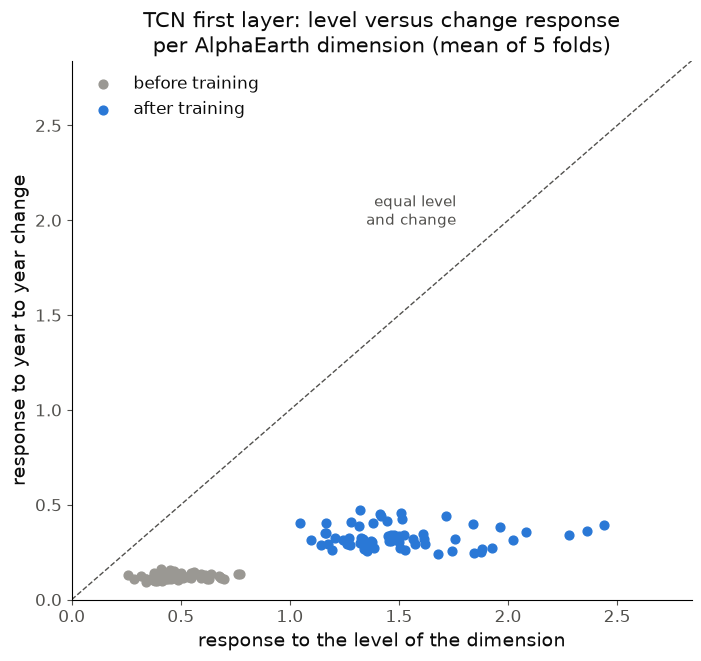

In [9]:
def level_change(w, scale):
    w = scale[:, :, None, None] * w
    level = np.sqrt((((w[..., 0] + w[..., 1]) / 2) ** 2).sum(axis=1)) * sum_std.mean(axis=1)
    change = np.sqrt((((w[..., 0] - w[..., 1]) / 2) ** 2).sum(axis=1)) * diff_std.mean(axis=1)
    return level, change   # each (fold, 64)


level, change = level_change(W, bn_scale)
# The trained BatchNorm scale goes on the starting weights too, so both clouds are in
# the same units and the only thing that differs between them is the conv weights.
level0, change0 = level_change(W_init, bn_scale)

change_share = change / (level + change)
change_share0 = change0 / (level0 + change0)
print(f"change share of the first layer response, trained: {change_share.mean():.1%} "
      f"(dims range {change_share.mean(0).min():.1%} to {change_share.mean(0).max():.1%})")
print(f"change share at initialization:                  {change_share0.mean():.1%}")

top_change = np.argsort(change_share.mean(0))[::-1][:5]
print("most change driven dims:", ", ".join(f"{DIM_NAMES[d]} ({change_share.mean(0)[d]:.0%})" for d in top_change))

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(level0.mean(0), change0.mean(0), s=40, color=C_INIT, label="before training", zorder=2)
ax.scatter(level.mean(0), change.mean(0), s=40, color=C_TCN, label="after training", zorder=3)
lim = max(level.max(), level0.max(), change.max(), change0.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.text(lim * 0.62, lim * 0.72, "equal level\nand change", ha="right", va="center", color=MUTED, fontsize=11)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("response to the level of the dimension")
ax.set_ylabel("response to year to year change")
ax.set_title("TCN first layer: level versus change response\nper AlphaEarth dimension (mean of 5 folds)")
ax.legend(frameon=False, loc="upper left")
save(fig, "first_layer_level_versus_change")
plt.show()

## 5. Permutation importance: what the whole network uses

Everything so far looks only at the first layer. After it come a second convolution, a ReLU (which throws away negative values), and a three layer head. The network can learn to ignore a first layer filter further down, so a big first layer weight doesn't guarantee the dimension affects the final prediction.

Permutation importance tests the whole model directly:

1. Score the validation pixels and compute AUPRC.
2. Take dimension `d` and shuffle it across pixels, so each pixel gets dimension `d` from some random other pixel. The shuffle covers all three years together, so a pixel's 2017 to 2019 history for `d` stays intact; it just belongs to the wrong pixel now. Every other input stays put.
3. Score again. The drop in AUPRC is how much the model relied on dimension `d`.

Shuffling keeps the dimension's distribution exactly the same (same values, different pixels), so the model never sees out of range inputs. Only the link between dimension `d` and the label is broken.

Details:

* It runs on every 5th validation pixel of each fold (about 2.4 million pixels), held out blocks the model never trained on. The positive rate in this sample is printed below.
* Each dimension is shuffled twice with different random orders, and the two drops are averaged.
* Distance to developed land is shuffled the same way as a reference point.
* One known weakness: AlphaEarth dimensions are correlated with each other. If `A12` and `A40` carry overlapping information, shuffling one lets the model fall back on the other, so both can look less important than the pair is together.

This is the slow cell (several minutes on the GPU). It saves its result to `permutation_importance.npz` and loads that on reruns. Delete the file to recompute.

In [10]:
PERM_CACHE = RUN / "permutation_importance.npz"
N_REPEATS = 2
device = "cuda" if torch.cuda.is_available() else "cpu"


def predict(model, emb, dist, batch=262_144):
    out = []
    with torch.no_grad():
        for s in range(0, len(emb), batch):
            out.append(torch.sigmoid(model(emb[s:s + batch], dist[s:s + batch]).squeeze(1)).cpu())
    return torch.cat(out).numpy()


def permutation_importance(k):
    d = RUN / f"fold_{k}"
    rows = np.load(d / "val_sample_rows.npy")
    emb_mm = np.load(ARRAY_DIR / "emb.npy", mmap_mode="r")
    dist_mm = np.load(ARRAY_DIR / "dist.npy", mmap_mode="r")
    y = np.load(ARRAY_DIR / "label.npy", mmap_mode="r")[rows].astype(np.int8)

    # distance is normalized with this fold's train stats, same as in training
    dist = (dist_mm[rows] - info[k]["dist_mean_m"]) / info[k]["dist_std_m"]
    emb = torch.from_numpy(np.asarray(emb_mm[rows])).to(device)  # float16, under 1 GB
    dist = torch.from_numpy(dist.astype(np.float32)).to(device)

    model = models.TemporalConvolutionalNetwork.load_from_checkpoint(d / "tcn_best.ckpt").to(device).eval()
    base = average_precision_score(y, predict(model, emb, dist))

    gen = torch.Generator(device=device).manual_seed(k)
    drops = np.zeros((N_DIMS + 1, N_REPEATS))   # last row is distance
    for i in range(N_DIMS + 1):
        for r in range(N_REPEATS):
            perm = torch.randperm(len(y), generator=gen, device=device)
            if i < N_DIMS:
                cols = [i + N_DIMS * t for t in range(N_YEARS)]  # this dim in every year
                saved = emb[:, cols].clone()
                emb[:, cols] = saved[perm]
                drops[i, r] = base - average_precision_score(y, predict(model, emb, dist))
                emb[:, cols] = saved
            else:
                drops[i, r] = base - average_precision_score(y, predict(model, emb, dist[perm]))
    return base, drops, len(y), int(y.sum())


if PERM_CACHE.exists():
    p = np.load(PERM_CACHE)
    perm_base, perm_drops, perm_n, perm_pos = p["base"], p["drops"], p["n_rows"], p["n_pos"]
else:
    res = [permutation_importance(k) for k in range(N_FOLDS)]
    perm_base = np.array([r[0] for r in res])
    perm_drops = np.stack([r[1] for r in res])   # (fold, 65, repeat)
    perm_n = np.array([r[2] for r in res])
    perm_pos = np.array([r[3] for r in res])
    np.savez(PERM_CACHE, base=perm_base, drops=perm_drops, n_rows=perm_n, n_pos=perm_pos)

perm = perm_drops.mean(axis=2)[:, :N_DIMS]       # (fold, 64)
perm_dist = perm_drops.mean(axis=2)[:, N_DIMS]
repeat_noise = np.abs(perm_drops[..., 0] - perm_drops[..., 1])[:, :N_DIMS].mean()

pd.DataFrame({
    "sample pixels": perm_n, "positives": perm_pos, "positive rate": perm_pos / perm_n,
    "AUPRC, nothing shuffled": perm_base, "AUPRC drop, distance shuffled": perm_dist,
    "largest drop, any dim": perm.max(axis=1), "median drop, all dims": np.median(perm, axis=1),
}, index=[f"fold {k}" for k in range(N_FOLDS)]).style.format({
    "sample pixels": "{:,}", "positives": "{:,}", "positive rate": "{:.3%}",
    "AUPRC, nothing shuffled": "{:.4f}", "AUPRC drop, distance shuffled": "{:.4f}",
    "largest drop, any dim": "{:.4f}", "median drop, all dims": "{:.4f}"})

,sample pixels,positives,positive rate,"AUPRC, nothing shuffled","AUPRC drop, distance shuffled","largest drop, any dim","median drop, all dims"
fold 0,"2,373,356","5,851",0.247%,0.0849,0.0255,0.0212,0.0075
fold 1,"2,369,025","7,810",0.330%,0.1212,0.0397,0.0352,0.0109
fold 2,"2,368,218","6,094",0.257%,0.1113,0.0370,0.0258,0.0082
fold 3,"2,370,848","6,133",0.259%,0.1178,0.0399,0.0357,0.0110
fold 4,"2,372,021","7,327",0.309%,0.1210,0.0284,0.0325,0.0092


To judge whether a drop is meaningful, compare it with the noise: the printout below gives the average gap between the two shuffles of the same dimension. A drop that's not much bigger than that is indistinguishable from zero.

It also adds up all 64 single dimension drops and divides by the unshuffled AUPRC. If each dimension contributed its own separate piece of the signal, the drops would add up to at most about 1. A total far above 1 means something else is going on. One cause is that dimensions work together (the network uses combinations of them). The other is a known weakness of permutation importance: AlphaEarth embeddings are unit length vectors with correlated coordinates, so swapping one coordinate in from another pixel makes an embedding that never occurs in real data. The model may react badly to that strange input whether or not it "relies" on the dimension. Both causes push every dimension's drop up, so read the drops as a **ranking**, not as each dimension's share of the model's skill.

average gap between the two shuffles of one dim: 0.00095 AUPRC
smallest mean drop over all 64 dims: 0.0022, median 0.0092, largest 0.0240
sum of the 64 drops / unshuffled AUPRC, per fold: [6.5 6.2 5.  6.4 5.6]


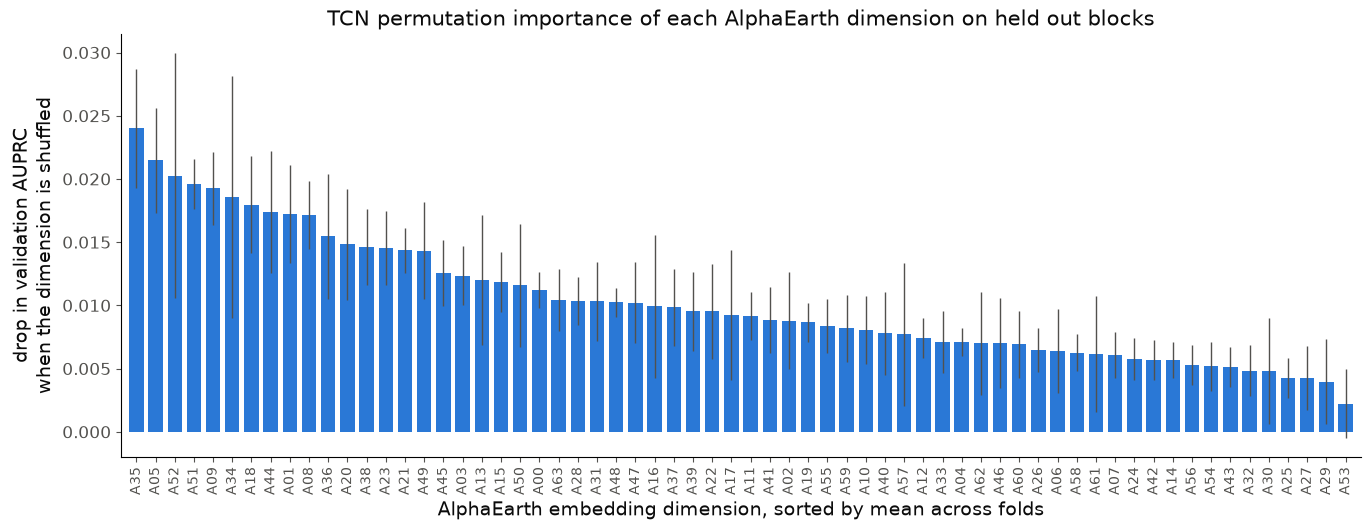

permutation importance: mean Spearman between folds 0.62, mean top 10 overlap 5.5 of 10 (chance about 1.6)
top 10: A35, A05, A52, A51, A09, A34, A18, A44, A01, A08


In [11]:
print(f"average gap between the two shuffles of one dim: {repeat_noise:.5f} AUPRC")
print(f"smallest mean drop over all 64 dims: {perm.mean(0).min():.4f}, median {np.median(perm.mean(0)):.4f}, "
      f"largest {perm.mean(0).max():.4f}")
print("sum of the 64 drops / unshuffled AUPRC, per fold:", np.round(perm.sum(axis=1) / perm_base, 1))
perm_order = ranked_bar(
    perm, C_TCN, "drop in validation AUPRC\nwhen the dimension is shuffled",
    "TCN permutation importance of each AlphaEarth dimension on held out blocks",
    "permutation_importance",
)
_, _, perm_rho, perm_overlap = fold_agreement(perm)
print(f"permutation importance: mean Spearman between folds {perm_rho:.2f}, "
      f"mean top 10 overlap {perm_overlap:.1f} of 10 (chance about 1.6)")
print("top 10:", ", ".join(DIM_NAMES[perm_order[:10]]))

### Do the weights and permutation importance agree?

If the first layer weights tell the same story as the whole network, the dimensions with the largest effective weight change should also lose the most AUPRC when shuffled. Each point below is one dimension, averaged over the 5 folds. The 5 dimensions with the largest permutation importance are labeled.

Spearman(effective weight change, permutation drop) per fold: [0.37 0.4  0.21 0.23 0.19]
on the 5 fold means: 0.27


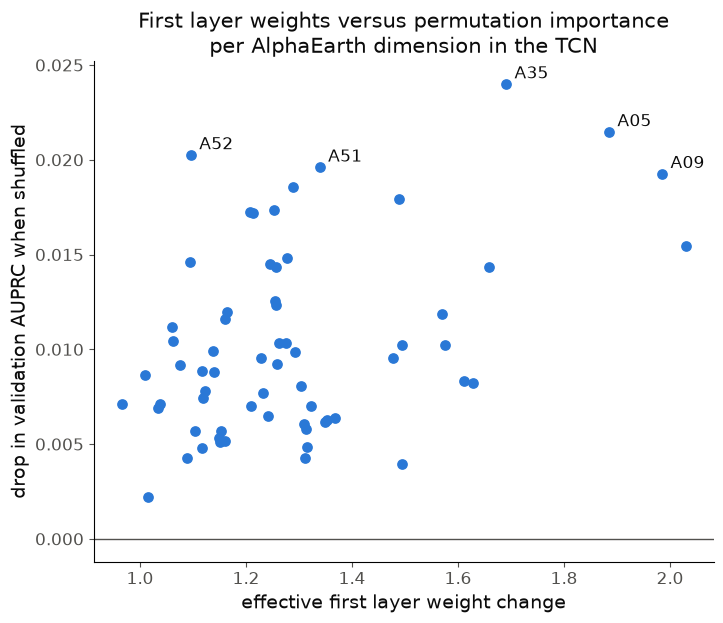

In [12]:
fold_rho_wp = [spearmanr(effective[k], perm[k])[0] for k in range(N_FOLDS)]
print("Spearman(effective weight change, permutation drop) per fold:", np.round(fold_rho_wp, 2))
print(f"on the 5 fold means: {spearmanr(effective.mean(0), perm.mean(0))[0]:.2f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(effective.mean(0), perm.mean(0), s=45, color=C_TCN)
for d in perm_order[:5]:
    ax.annotate(DIM_NAMES[d], (effective.mean(0)[d], perm.mean(0)[d]), xytext=(6, 4),
                textcoords="offset points", fontsize=12, color=INK)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("effective first layer weight change")
ax.set_ylabel("drop in validation AUPRC when shuffled")
ax.set_title("First layer weights versus permutation importance\nper AlphaEarth dimension in the TCN")
save(fig, "weights_versus_permutation")
plt.show()

## 6. Comparison with the linear baseline

The linear model (`models.SimpleLinearModel`) is a single `nn.Linear(193, 1)` on the same inputs: distance plus the 192 embedding columns, trained on the same folds with the same loss. Its weights are the easiest possible thing to interpret: one number per input column.

To compare across dimensions, each coefficient is multiplied by its column's standard deviation (that's what the coefficient would be if the inputs had been standardized). Then the three years are combined into one number per dimension, the L2 norm over years. Unlike the TCN, a linear model can't build any interactions between dimensions, so if the two models agree on which dimensions matter, the signal in those dimensions is probably fairly simple.

linear standardized coefficients: mean Spearman between folds 0.90, mean top 10 overlap 6.8 of 10
linear distance coefficient (per train std of distance), mean of folds: -3.274
linear top 10: A18, A23, A05, A01, A35, A13, A00, A51, A15, A36


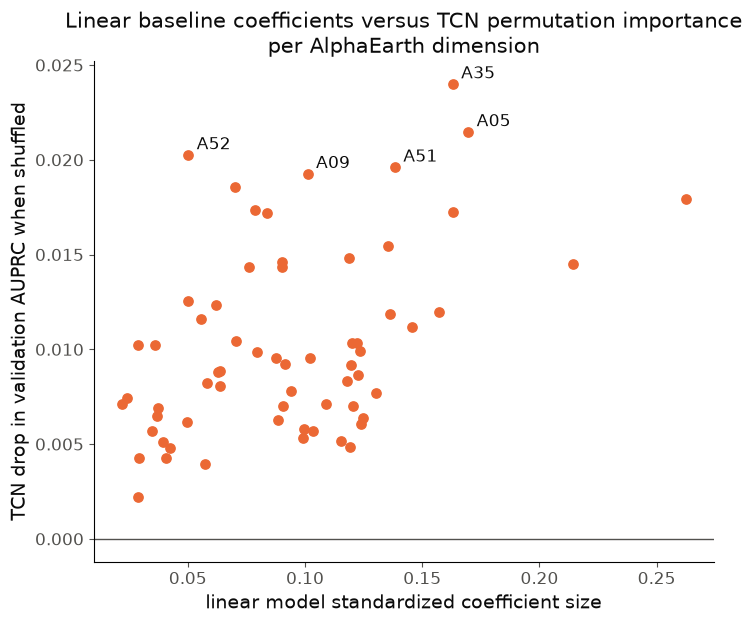

In [13]:
lin_emb = lin_coef[:, 1:].reshape(N_FOLDS, N_YEARS, N_DIMS) * col_std
lin_score = np.sqrt((lin_emb ** 2).sum(axis=1))   # (fold, 64)
_, _, lin_rho, lin_overlap = fold_agreement(lin_score)
print(f"linear standardized coefficients: mean Spearman between folds {lin_rho:.2f}, "
      f"mean top 10 overlap {lin_overlap:.1f} of 10")
print(f"linear distance coefficient (per train std of distance), mean of folds: {lin_coef[:, 0].mean():.3f}")
print("linear top 10:", ", ".join(DIM_NAMES[np.argsort(lin_score.mean(0))[::-1][:10]]))

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(lin_score.mean(0), perm.mean(0), s=45, color=C_LIN)
for d in perm_order[:5]:
    ax.annotate(DIM_NAMES[d], (lin_score.mean(0)[d], perm.mean(0)[d]), xytext=(6, 4),
                textcoords="offset points", fontsize=12, color=INK)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("linear model standardized coefficient size")
ax.set_ylabel("TCN drop in validation AUPRC when shuffled")
ax.set_title("Linear baseline coefficients versus TCN permutation importance\nper AlphaEarth dimension")
save(fig, "linear_versus_permutation")
plt.show()

### Every ranking side by side

Spearman correlation between every pair of per dimension scores, computed within each fold and then averaged over the 5 folds.

In [14]:
all_scores = {"raw first layer norm": raw, "effective weight change": effective,
              "TCN permutation drop": perm, "linear coefficient": lin_score}
pd.DataFrame([[mean_fold_spearman(all_scores[a], all_scores[b]) for b in all_scores] for a in all_scores],
             index=all_scores.keys(), columns=all_scores.keys()).round(2)

,raw first layer norm,effective weight change,TCN permutation drop,linear coefficient
raw first layer norm,1.00,-0.10,-0.17,-0.26
effective weight change,-0.10,1.00,0.28,0.24
TCN permutation drop,-0.17,0.28,1.00,0.32
linear coefficient,-0.26,0.24,0.32,1.00


## Summary

Numbers below are from the run in `results/tcn_weight_analysis` (5 spatially blocked folds, `data/arrays_2019_2024`, embeddings 2017 to 2019, validation positive rate 0.25% to 0.33%).

**The models learned something.** TCN validation AUPRC is 0.086 to 0.123 across folds (mean 0.112), against 0.070 to 0.099 (mean 0.087) for the linear baseline. Random guessing would score about 0.003.

**First layer weight sizes are a poor guide to importance in this model.**

* The random starting weights aren't the problem. Training moved the weights to about 3 times their starting size, and the raw ranking has nothing to do with the starting one (Spearman about 0).
* The real problem is input scale. Corrected for input spread and BatchNorm, the score's ranking matches the input std ranking with Spearman 0.81. How far a dimension's weights moved runs the opposite way (Spearman with std about −0.64), but only partly offsets a 2.8x spread in input std. The most likely cause is Adam, which moves every weight by about the same amount per step whatever the size of its gradient.
* So the very high fold to fold agreement of the weight ranking (Spearman 0.91) mostly reflects that every fold sees the same input statistics. It isn't evidence of a learned preference.
* Weight based and permutation based rankings agree only weakly (Spearman 0.28).

**The first layer mostly reads levels, not year to year change.** About 18% of its response comes from year to year differences, slightly *less* than the 21% at initialization. Training didn't turn the first layer into a change detector. Whatever change signal the model uses has to come from deeper layers or from the level of the embedding (where a pixel sits in embedding space).

**Permutation importance: the model uses all 64 dimensions, with a moderate head and no small dominant subset.**

* Every dimension's mean drop (0.002 to 0.024 AUPRC) is above the shuffle noise of about 0.001. The median dimension costs 0.009 AUPRC when shuffled, the top one (`A35`) 0.024, about 2.6 times the median.
* Distance to developed land costs 0.026 to 0.040 when shuffled, more than any single embedding dimension.
* The ranking is moderately stable across folds: Spearman 0.62, and on average 5.5 of each fold's top 10 dimensions appear in another fold's top 10 (chance would be about 1.6).
* The drops add up to 5 to 6.5 times the unshuffled AUPRC, so single dimension drops overstate each dimension's own share (see the caveat in section 5).

**Dimensions that come up repeatedly.** `A05` and `A35` are in the top 10 by effective weight change, by permutation importance and by the linear model's coefficients. `A01`, `A18` and `A51` are in the top 10 by both permutation importance and the linear model, and `A09` by both permutation importance and the weights. If we want to interpret particular dimensions, start with these six, not with the weight based top 10.

**What would sharpen this.**

1. To make first layer weights mean something, train with weight decay, or with a group lasso penalty on each dimension's slice of `W` (a penalty on the size of each dimension's whole block of weights, which pushes unused dimensions to exactly zero), and standardize the embedding inputs first. Then weight size and importance line up by construction.
2. Permute groups of correlated dimensions together (cluster the 64 dimensions by their correlation first). That keeps the shuffled embeddings closer to real ones and avoids one dimension standing in for a shuffled twin.
3. Map `A05`, `A35` and the other recurring dimensions over Florida's wetlands, and compare them with NLCD classes and distance to developed land, to see what they pick up on.